# Emoji vendor classification — Vision Transformer (ViT) fine-tuning

**Course:** Computer Vision (IDSI51006) — BSc AIDAMS, ESSEC / CentraleSupélec, 2026
**Kaggle competition:** [2 - Computer Vision 2026 - BSc AIDAMS - FINAL PROJ](https://www.kaggle.com/t/521819a4ff2d4c7a81511fdcb4709a50)
**Group:** _Name 1, Name 2, Name 3, Name 4_ (also set `GROUP_MEMBERS` in the configuration cell)

**Task:** predict which provider (apple, google, whatsapp, facebook, samsung, mozilla, messenger) drew each emoji image. Kaggle metric: accuracy.

**Final approach:** a pretrained Vision Transformer (`google/vit-base-patch16-224-in21k`) fine-tuned on the training images, with a class-weighted loss to handle class imbalance.

This notebook does the whole pipeline from top to bottom: setup → data download → preprocessing → training → validation → test predictions → `submission.csv` → `README.md`. Our earlier experiments (custom CNN, ResNet101 transfer learning, data augmentation) are kept in a separate experiments notebook and are described in the report.

**Contents**
0. How to run (reproducibility)
1. Setup
2. Data
3. Preprocessing
4. Train / validation split and class weights
5. Model
6. Training
7. Validation results
8. Test predictions and `submission.csv`
9. Generate `README.md` and `requirements.txt`
10. Download the output files

## 0. How to run (reproducibility)

The notebook is designed for **Google Colab** so it runs the same way on any computer (Windows, macOS or Linux): everything runs in the browser and nothing has to be installed locally.

**Step 1 — Open the notebook in Colab**
- From GitHub: open `https://colab.research.google.com/github/georgerieh/computer-vision-class/blob/main/emoji_vit_colab_v2.ipynb`
- Or: in Colab, *File → Upload notebook* and choose this `.ipynb` file.

**Step 2 — Choose the runtime**
*Runtime → Change runtime type*:
- **Hardware accelerator: T4 GPU** (training a ViT on CPU would take many hours).
- **Runtime version: `2026.07`** (recommended). Pinning the Colab version freezes Python (3.12) and TensorFlow (2.20.0), so later Colab updates cannot break the notebook. Leaving it on "Latest" also works in most cases: the install cell below forces the exact library versions anyway.

**Step 3 — Give access to the data** (choose ONE option)
- **Option A — Kaggle API key (automatic download).**
  1. On Kaggle: make sure you joined the competition and accepted its rules (otherwise the download is refused).
  2. Kaggle → *Settings → API → Create New Token*.
  3. In Colab, open the 🔑 **Secrets** panel (left sidebar) and add either `KAGGLE_USERNAME` + `KAGGLE_KEY` (values from the `kaggle.json` file), or `KAGGLE_API_TOKEN` (newer token type). Switch on "Notebook access" for each secret.
- **Option B — Upload the zip manually.** Download the data zip from the competition's *Data* tab and drag it into the Colab *Files* panel (folder `/content`). The notebook finds and unzips it automatically. The zip is about 257 MB, so wait for the upload to finish before running.

**Step 4 — Run everything**
1. *Runtime → Run all*.
2. **First run only:** the install cell installs the pinned library versions and then restarts the session on purpose (Colab may show "Your session crashed" — this is expected). Then click *Runtime → Run all* **a second time**. From then on the install cell detects the correct versions and does nothing.
3. The whole run takes roughly 30–60 minutes on a T4 GPU (most of it is training).

**Step 5 — Outputs**
At the end, `submission.csv`, `README.md` and `requirements.txt` are downloaded to your computer through the browser (nothing is written to Google Drive). If the browser asks whether the page may download multiple files, click *Allow*. All outputs are also kept in `/content/outputs/` while the session is open.

**What "reproducible" means here**
- Library versions are pinned (install cell) and printed.
- All randomness we control is seeded with `SEED = 42`: the train/validation split, the shuffling order, and the initialisation of the new classification layer.
- GPUs still use some non-deterministic operations for speed, so a rerun can differ slightly (typically a few tenths of a percent of accuracy). Setting `DETERMINISTIC = True` in the configuration cell removes this, at the cost of slower training.
- All settings (seed, image size, epochs, learning rate, …) are in one configuration cell (section 1.3).

## 1. Setup

### 1.1 Install pinned library versions

**Why:** these libraries change quickly, so we lock exact versions.
- Recent `transformers` releases (v5+) no longer include TensorFlow models, so we pin `transformers` 4.57.1, which still has `TFViTForImageClassification`.
- `tf-keras` (Keras 2) is required by the TensorFlow models in `transformers`; Colab's default Keras 3 does not work with them.

If anything had to be installed, the cell restarts the session. Run all cells again after that.

In [ ]:
# 1.1 Install pinned versions (installs only what is missing or different, then restarts once)
import importlib.metadata as metadata
import os
import subprocess
import sys

PINNED_VERSIONS = {
    "tensorflow": "2.20.0",
    "tf-keras": "2.20.1",       # Keras 2 for TensorFlow 2.20 (needed by transformers' TF models)
    "transformers": "4.57.1",   # last 4.x line; v5 removed TensorFlow support
    "scikit-learn": "1.6.1",
    "kagglehub": "1.0.2",
}

def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return None

to_install = [f"{pkg}=={ver}" for pkg, ver in PINNED_VERSIONS.items()
              if installed_version(pkg) != ver]

if to_install:
    print("Installing:", " ".join(to_install))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *to_install])
    print("\nInstallation done. Restarting the session so the new versions are used.")
    print(">>> When the session has restarted: Runtime -> Run all again. <<<")
    os.kill(os.getpid(), 9)   # restart the Python process (Colab reconnects automatically)
else:
    print("All pinned versions already installed:")
    for pkg, ver in PINNED_VERSIONS.items():
        print(f"  {pkg}=={ver}")

All pinned versions already installed:
  tensorflow==2.20.0
  tf-keras==2.20.1
  transformers==4.57.1
  scikit-learn==1.6.1
  kagglehub==1.0.2


### 1.2 Imports

`TF_USE_LEGACY_KERAS=1` must be set **before** TensorFlow is imported, so that `tf.keras` and `transformers` both use Keras 2 (`tf-keras`).

In [ ]:
# 1.2 Imports
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"   # use Keras 2 (tf-keras) everywhere
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info messages

import math
import platform
import shutil
import time
import zipfile
from collections import Counter
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import tensorflow as tf
import tf_keras as keras

import sklearn
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import transformers
from transformers import TFViTForImageClassification, ViTImageProcessor, create_optimizer

import kagglehub

try:
    from google.colab import files, userdata
    IN_COLAB = True
except ImportError:          # running outside Colab (e.g. local Jupyter)
    IN_COLAB = False

# Record the exact environment (also written to README.md and requirements.txt at the end)
ENV_VERSIONS = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "tf-keras": keras.__version__,
    "transformers": transformers.__version__,
    "scikit-learn": sklearn.__version__,
    "kagglehub": kagglehub.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": PIL.__version__,
    "matplotlib": matplotlib.__version__,
}
for name, version in ENV_VERSIONS.items():
    print(f"{name:<13} {version}")

mismatches = {p: (ENV_VERSIONS.get(p), v) for p, v in PINNED_VERSIONS.items()
              if ENV_VERSIONS.get(p) != v}
if mismatches:
    print("\nWARNING - versions differ from the pinned ones (installed, pinned):", mismatches)
    print("Re-run cell 1.1, or restart the session and run all again.")

python        3.13.15
tensorflow    2.20.0
tf-keras      2.20.1
transformers  4.57.1
scikit-learn  1.6.1
kagglehub     1.0.2
numpy         2.1.3
pandas        2.2.3
pillow        11.3.0
matplotlib    3.10.0


### 1.3 Configuration

Every setting that affects the results is defined here, so a rerun uses exactly the same choices. The reasons for each value are in the comments and in the section where it is used.

In [ ]:
# 1.3 Configuration
SEED = 42
DETERMINISTIC = False      # True = bit-for-bit identical GPU runs, but slower training

# Project information (used in README.md)
GROUP_MEMBERS = ["Name 1", "Name 2", "Name 3", "Name 4"]   # TODO: fill in
KAGGLE_TEAM_NAME = "TODO"                                   # TODO: fill in
REPO_URL = "https://github.com/georgerieh/computer-vision-class"
NOTEBOOK_NAME = "emoji_vit_colab_v2.ipynb"
COLAB_URL = "https://colab.research.google.com/github/georgerieh/computer-vision-class/blob/main/" + NOTEBOOK_NAME
COMPETITION_SLUG = "2-computer-vision-2026-b-sc-aidams-final-proj"
COMPETITION_URL = "https://www.kaggle.com/t/521819a4ff2d4c7a81511fdcb4709a50"

# Classes (fixed order = the integer ids used by the model)
CLASSES = ["apple", "google", "whatsapp", "facebook", "samsung", "mozilla", "messenger"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}
ID_TO_CLASS = {i: name for i, name in enumerate(CLASSES)}

# Preprocessing
BACKGROUND_COLOR = (255, 255, 255)   # transparent pixels are filled with white (see section 3)

# Model and training
MODEL_NAME = "google/vit-base-patch16-224-in21k"   # ViT-Base, 16x16 patches, pretrained on ImageNet-21k
VAL_SIZE = 0.2              # 20% of the labelled images held out for validation (stratified)
BATCH_SIZE = 16             # fits in the memory of a free Colab T4 GPU
EPOCHS = 5                  # maximum number of epochs (early stopping may stop earlier)
LEARNING_RATE = 2e-5        # small learning rate: we adjust pretrained weights, not learn from scratch
WEIGHT_DECAY = 0.01         # AdamW weight decay (light regularisation)
WARMUP_RATIO = 0.1          # first 10% of steps: learning rate rises from 0 to LEARNING_RATE
EARLY_STOP_PATIENCE = 2     # stop if validation accuracy has not improved for 2 epochs
USE_CLASS_WEIGHTS = True    # weight the loss by inverse class frequency (section 4)

# Run options
TRAIN_MODEL = True          # False = reuse a model already saved in MODEL_DIR (skips training)
DOWNLOAD_MODEL = False      # True = also download the trained model as a zip (~300 MB)

# Paths
WORK_DIR = Path("/content") if IN_COLAB else Path.cwd()
DATA_ROOT = WORK_DIR / "data"
OUTPUT_DIR = WORK_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "vit_emoji_model"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", WORK_DIR)
print("Outputs will be saved in:", OUTPUT_DIR)

Working directory: /content
Outputs will be saved in: /content/outputs


### 1.4 Seeds and GPU check

`keras.utils.set_random_seed` seeds Python's `random`, NumPy and TensorFlow in one call.

In [ ]:
# 1.4 Seeds and hardware
keras.utils.set_random_seed(SEED)
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic GPU operations: ON")

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("GPU found:", [tf.config.experimental.get_device_details(g).get("device_name", g.name) for g in gpus])
else:
    print("WARNING: no GPU found. Training will be very slow.")
    print("In Colab: Runtime -> Change runtime type -> T4 GPU, then run all again.")

GPU found: ['Tesla T4']


## 2. Data

### 2.1 Download / locate the data

The cell tries, in this order:
1. data already extracted in `data/` (when the notebook is re-run in the same session);
2. a competition zip uploaded manually to `/content` (Option B in section 0);
3. download from Kaggle with `kagglehub`, using the Kaggle credentials stored in Colab Secrets (Option A).

The original image files are never modified. Preprocessing happens in memory only.

In [ ]:
# 2.1 Locate or download the competition data

def find_data_dir(root):
    """Return the folder that contains train_labels.csv (searching sub-folders), or None."""
    root = Path(root)
    if not root.exists():
        return None
    hits = sorted(root.rglob("train_labels.csv"))
    return hits[0].parent if hits else None

def set_kaggle_credentials():
    """Copy Kaggle credentials from Colab Secrets into environment variables for kagglehub."""
    if IN_COLAB:
        for name in ["KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"]:
            if os.environ.get(name):
                continue
            try:
                value = userdata.get(name)
            except Exception:      # secret missing or notebook access not granted
                value = None
            if value:
                os.environ[name] = value
    has_credentials = (
        (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"))
        or os.environ.get("KAGGLE_API_TOKEN")
        or (Path.home() / ".kaggle" / "kaggle.json").exists()
    )
    if not has_credentials:
        raise RuntimeError(
            "No Kaggle credentials and no data zip found.\n"
            "Either add KAGGLE_USERNAME + KAGGLE_KEY (or KAGGLE_API_TOKEN) in Colab Secrets "
            "with notebook access ON, or upload the competition zip to /content, then re-run this cell."
        )

def get_data_dir():
    # 1) Already extracted earlier in this session
    data_dir = find_data_dir(DATA_ROOT)
    if data_dir:
        print("Using data already extracted in", data_dir)
        return data_dir
    # 2) Zip uploaded manually to the working directory
    for zip_path in sorted(WORK_DIR.glob("*.zip")):
        with zipfile.ZipFile(zip_path) as zf:
            if any(name.endswith("train_labels.csv") for name in zf.namelist()):
                print(f"Extracting {zip_path.name} ...")
                zf.extractall(DATA_ROOT)
                return find_data_dir(DATA_ROOT)
    # 3) Download from Kaggle
    set_kaggle_credentials()
    print("Downloading from Kaggle ...")
    download_path = kagglehub.competition_download(COMPETITION_SLUG)
    return find_data_dir(download_path)

DATA_DIR = get_data_dir()
assert DATA_DIR is not None, "train_labels.csv not found in the downloaded/extracted data."
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
print("Data folder:", DATA_DIR)
print("Contents:", sorted(p.name for p in DATA_DIR.iterdir()))

Data folder: /root/.cache/kagglehub/competitions/2-computer-vision-2026-b-sc-aidams-final-proj
Contents: ['test', 'train', 'train_labels.csv']


### 2.2 Labels and file checks

Image file names are the ids (e.g. `00001.png` → Id 1). We check that every label has an image, that the classes are the expected ones, and that the test ids match `sample_submission.csv`.

In [ ]:
# 2.2 Labels, file lists and consistency checks
labels_df = pd.read_csv(DATA_DIR / "train_labels.csv")
assert list(labels_df.columns[:2]) == ["Id", "Label"], labels_df.columns
assert set(labels_df["Label"]) == set(CLASSES), set(labels_df["Label"]) ^ set(CLASSES)

train_files = {int(p.stem): p for p in TRAIN_DIR.glob("*.png")}
test_files = {int(p.stem): p for p in TEST_DIR.glob("*.png")}

labels_df["path"] = labels_df["Id"].map(train_files)
assert labels_df["path"].notna().all(), "Some labelled ids have no image file."
labels_df["y"] = labels_df["Label"].map(CLASS_TO_ID).astype("int32")

# Submission format and test-id order come from sample_submission.csv when it exists
sample_path = DATA_DIR / "sample_submission.csv"
if sample_path.exists():
    sample_submission = pd.read_csv(sample_path)
    ID_COL, LABEL_COL = sample_submission.columns[:2]
    test_ids = sample_submission[ID_COL].astype(int).tolist()
    assert set(test_ids) == set(test_files), "Test images and sample_submission ids differ."
else:
    ID_COL, LABEL_COL = "Id", "Label"
    test_ids = sorted(test_files)
test_paths = [test_files[i] for i in test_ids]

print(f"Train images: {len(labels_df)} | Test images: {len(test_paths)}")
print(f"Submission columns: {ID_COL}, {LABEL_COL}")
labels_df.head()

Train images: 9879 | Test images: 9879
Submission columns: Id, Label


,Id,Label,path,y
0,1,samsung,/root/.cache/kagglehub/competitions/2-computer...,4
1,2,apple,/root/.cache/kagglehub/competitions/2-computer...,0
2,3,facebook,/root/.cache/kagglehub/competitions/2-computer...,3
3,4,facebook,/root/.cache/kagglehub/competitions/2-computer...,3
4,5,google,/root/.cache/kagglehub/competitions/2-computer...,1


### 2.3 Quick look at the data

Two things matter for the design: the **class imbalance** (mozilla and messenger are much rarer) and the **image format** (PNG with a transparent background, varying sizes).

,images,share
Label,,
apple,1924,0.195
google,1877,0.190
whatsapp,1644,0.166
facebook,1667,0.169
samsung,1790,0.181
mozilla,397,0.040
messenger,580,0.059


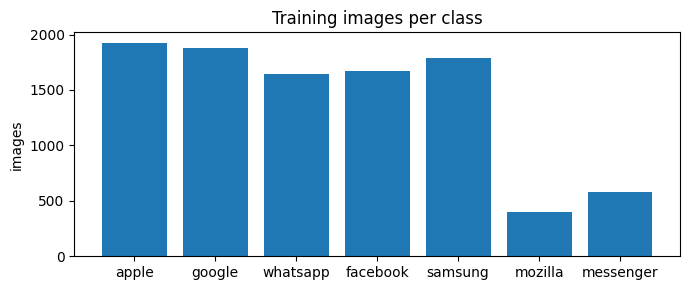

In [ ]:
# 2.3a Class distribution
counts = labels_df["Label"].value_counts().reindex(CLASSES)
display(counts.to_frame("images").assign(share=lambda d: (d["images"] / d["images"].sum()).round(3)))

plt.figure(figsize=(7, 3))
plt.bar(counts.index, counts.values)
plt.title("Training images per class")
plt.ylabel("images")
plt.tight_layout()
plt.show()

In [ ]:
# 2.3b Image modes and sizes (random sample of 500 training images, for speed)
rng_look = np.random.default_rng(SEED)
sample_paths = rng_look.choice(labels_df["path"].to_numpy(), size=500, replace=False)
modes, sizes = Counter(), Counter()
for p in sample_paths:
    with Image.open(p) as im:
        modes[im.mode] += 1
        sizes[im.size] += 1
print("Image modes:", dict(modes))
print("Most common sizes (width, height):", sizes.most_common(5))

Image modes: {'RGBA': 400, 'LA': 3, 'P': 96, 'RGB': 1}
Most common sizes (width, height): [((72, 72), 295), ((240, 240), 127), ((160, 160), 73), ((72, 68), 5)]


## 3. Preprocessing

**Decisions and reasons**
- **Transparent background → white.** The images are PNGs with an alpha (transparency) channel, but the model takes 3-channel RGB input. Simply dropping the alpha channel exposes whatever colour is stored under the transparent pixels (often black or noise), which can differ between images. We therefore paste every image onto the same white background. The **same function is used for training and test images**, so both sets look identical to the model.
- **Resize and normalise exactly like the pretrained model expects.** The ViT was pretrained on 224×224 images normalised with specific mean/std values. We read these settings from the model's `ViTImageProcessor`, so they always match the checkpoint.
- **No inversion of colours.** Inverting (1 − pixel) helped our CNN trained from scratch. The pretrained ViT expects natural-looking images, so we keep the original colours.
- **No data augmentation.** The images are very homogeneous (centred emoji, same background, similar scale). In our experiments, augmentation (zoom, flips, rotation, brightness) lowered validation accuracy, so it is not used.
- **Memory:** images are stored once as 224×224 `uint8` arrays (about 1.5 GB for the training set). They are converted to normalised floats batch by batch during training.

In [ ]:
# 3.1 Preprocessing functions
processor = ViTImageProcessor.from_pretrained(MODEL_NAME)
IMG_H, IMG_W = processor.size["height"], processor.size["width"]
RESAMPLE = Image.Resampling(int(processor.resample))
RESCALE = float(processor.rescale_factor)                    # 1/255
MEAN = tf.constant(processor.image_mean, dtype=tf.float32)
STD = tf.constant(processor.image_std, dtype=tf.float32)
print(f"Input size {IMG_H}x{IMG_W} | resample {RESAMPLE.name} | mean {processor.image_mean} | std {processor.image_std}")

def load_rgb(path, background=BACKGROUND_COLOR):
    """Open a PNG and paste it onto a solid background -> RGB image (alpha removed consistently)."""
    with Image.open(path) as im:
        im = im.convert("RGBA")
        canvas = Image.new("RGBA", im.size, tuple(background) + (255,))
        canvas.alpha_composite(im)
        return canvas.convert("RGB")

def load_resized(path):
    """RGB image resized to the model input size, as a uint8 array (H, W, 3)."""
    return np.asarray(load_rgb(path).resize((IMG_W, IMG_H), RESAMPLE), dtype=np.uint8)

def load_images(paths, desc="Loading images"):
    images = np.empty((len(paths), IMG_H, IMG_W, 3), dtype=np.uint8)
    for i, p in enumerate(tqdm(paths, desc=desc)):
        images[i] = load_resized(p)
    return images

def normalize(image_uint8):
    """uint8 (H, W, 3) -> float32 (3, H, W), scaled and normalised like ViTImageProcessor."""
    x = tf.cast(image_uint8, tf.float32) * RESCALE
    x = (x - MEAN) / STD
    return tf.transpose(x, [2, 0, 1])   # the TF ViT model expects channels first

Input size 224x224 | resample BILINEAR | mean [0.5, 0.5, 0.5] | std [0.5, 0.5, 0.5]


**Sanity check:** our fast pipeline (resize once, normalise on the fly) must give the same numbers as the official `ViTImageProcessor`. The maximum difference should be close to 0.

In [ ]:
# 3.2 Check that our preprocessing matches the official processor
check_path = labels_df["path"].iloc[0]
official = processor(images=load_rgb(check_path), return_tensors="np")["pixel_values"][0]
ours = normalize(load_resized(check_path)).numpy()
max_diff = float(np.abs(official - ours).max())
print("Shapes:", official.shape, ours.shape, "| max absolute difference:", round(max_diff, 5))
if max_diff > 0.05:
    print("WARNING: preprocessing differs from ViTImageProcessor - check the resize settings.")

Shapes: (3, 224, 224) (3, 224, 224) | max absolute difference: 0.0


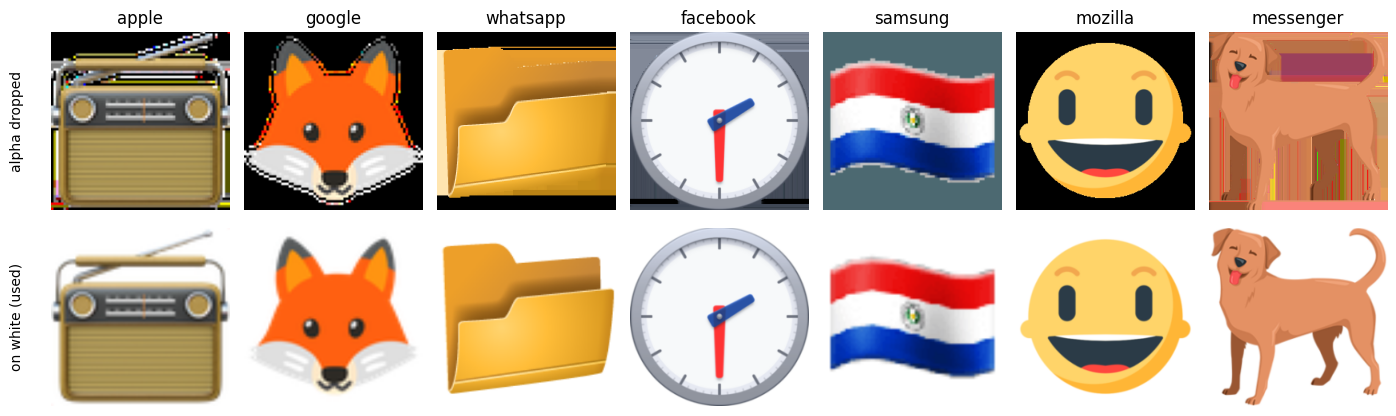

In [ ]:
# 3.3 Visual check: alpha channel simply dropped vs. pasted on white (one example per class)
fig, axes = plt.subplots(2, len(CLASSES), figsize=(2 * len(CLASSES), 4.4))
for j, cls in enumerate(CLASSES):
    p = labels_df.loc[labels_df["Label"] == cls, "path"].iloc[0]
    with Image.open(p) as im:
        dropped = im.convert("RGBA").convert("RGB")   # naive: alpha removed, hidden colours exposed
    axes[0, j].imshow(dropped)
    axes[1, j].imshow(load_resized(p))
    axes[0, j].set_title(cls)
    for ax in axes[:, j]:
        ax.axis("off")
axes[0, 0].text(-0.15, 0.5, "alpha dropped", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.15, 0.5, "on white (used)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout()
plt.show()

1 - image

In [ ]:
# 3.4 Load all training images into memory (about 1-2 minutes)
X_all = load_images(labels_df["path"].tolist(), desc="Train images")
y_all = labels_df["y"].to_numpy()
print("X_all:", X_all.shape, X_all.dtype, f"({X_all.nbytes / 1e9:.2f} GB) | y_all:", y_all.shape)

Train images:   0%|          | 0/9879 [00:00<?, ?it/s]

X_all: (9879, 224, 224, 3) uint8 (1.49 GB) | y_all: (9879,)


## 4. Train / validation split and class weights

- **Stratified 80/20 split** with a fixed seed: the validation set keeps the same class proportions as the full data (important for the rare classes). We use the validation set to choose the best epoch and to measure accuracy, since the test labels are hidden.
- **Class weights ("balanced")**: weight = n_samples / (n_classes × n_samples_of_class). Rare classes (mozilla, messenger) get a larger weight in the loss, so the model is penalised more for missing them. We compared this with undersampling every class to the size of the smallest one; class weights kept all the data and worked better.

In [ ]:
# 4.1 Stratified split
idx_train, idx_val = train_test_split(
    np.arange(len(y_all)), test_size=VAL_SIZE, stratify=y_all, random_state=SEED
)
X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
ids_val = labels_df["Id"].to_numpy()[idx_val]

print(f"Train: {len(y_train)} images | Validation: {len(y_val)} images")
print(pd.DataFrame({
    "train": pd.Series(y_train).map(ID_TO_CLASS).value_counts(),
    "validation": pd.Series(y_val).map(ID_TO_CLASS).value_counts(),
}).reindex(CLASSES))

Train: 7903 images | Validation: 1976 images
           train  validation
apple       1539         385
google      1501         376
whatsapp    1315         329
facebook    1334         333
samsung     1432         358
mozilla      318          79
messenger    464         116


In [ ]:
# 4.2 Class weights (computed on the training part only)
if USE_CLASS_WEIGHTS:
    class_weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
else:
    class_weights = np.ones(len(CLASSES))
class_weights = class_weights.astype("float32")
print(pd.Series(class_weights, index=CLASSES, name="class weight").round(3))

apple        0.734
google       0.752
whatsapp     0.859
facebook     0.846
samsung      0.788
mozilla      3.550
messenger    2.433
Name: class weight, dtype: float32


## 5. Model

**Why a Vision Transformer:** in our experiments a CNN trained from scratch and a frozen ResNet101 with a new head reached about 0.6–0.7 validation accuracy, while fine-tuning this pretrained ViT reached about 0.90. The ViT splits the image into 16×16 patches and uses self-attention, so every patch can be compared with every other patch. This suits a task where the class depends on the global drawing style (outlines, shading, colour palette) rather than on what the emoji shows.

**Setup**
- `TFViTForImageClassification` = pretrained ViT encoder + a **new linear classification layer with 7 outputs** (randomly initialised, seeded). All layers are fine-tuned.
- **Optimizer:** AdamW (Adam with weight decay), learning rate warm-up over the first 10% of steps, then linear decay to 0. The warm-up stops the random new head from producing large updates that would damage the pretrained weights early on.
- **Loss:** sparse categorical cross-entropy computed on the logits, multiplied by the class weight of each image's true class.
- **Metrics:** accuracy (the Kaggle metric) and top-3 accuracy.

**Loading note:** the model is loaded from the checkpoint's TensorFlow weights file (`tf_model.h5`) with `use_safetensors=False`. Loading the `model.safetensors` file into the TensorFlow model fails with the current `safetensors` library (`TypeError: 'builtins.safe_open' object is not iterable`). Both files contain the same pretrained weights.

In [ ]:
# 5.1 Build the model and the input pipelines
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(images, labels=None, shuffle=False, seed=SEED):
    """tf.data pipeline: uint8 images -> normalised float tensors, in batches.
    The shuffle order is seeded, so it is the same on every run."""
    rng = np.random.default_rng(seed)
    image_spec = tf.TensorSpec(shape=(IMG_H, IMG_W, 3), dtype=tf.uint8)

    def generator():
        order = rng.permutation(len(images)) if shuffle else np.arange(len(images))
        for i in order:
            if labels is None:
                yield images[i]
            else:
                yield images[i], labels[i]

    if labels is None:
        ds = tf.data.Dataset.from_generator(generator, output_signature=image_spec)
        ds = ds.map(normalize, num_parallel_calls=AUTOTUNE)
    else:
        labels = np.asarray(labels, dtype=np.int32)
        ds = tf.data.Dataset.from_generator(
            generator, output_signature=(image_spec, tf.TensorSpec(shape=(), dtype=tf.int32)))
        ds = ds.map(lambda x, y: (normalize(x), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds = make_dataset(X_val, y_val, shuffle=False)

def build_model():
    keras.utils.set_random_seed(SEED)   # same initial weights for the new classification layer
    return TFViTForImageClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(CLASSES),
        id2label=ID_TO_CLASS,
        label2id=CLASS_TO_ID,
        ignore_mismatched_sizes=True,
        use_safetensors=False,   # load the TensorFlow weights file (tf_model.h5); see note in section 5
    )

if TRAIN_MODEL:
    model = build_model()
else:
    assert MODEL_DIR.exists(), f"TRAIN_MODEL=False but no saved model in {MODEL_DIR}"
    model = TFViTForImageClassification.from_pretrained(str(MODEL_DIR), use_safetensors=False)
    print("Loaded saved model from", MODEL_DIR)

Some layers from the model checkpoint at google/vit-base-patch16-224-in21k were not used when initializing TFViTForImageClassification: ['vit/pooler/dense/kernel:0', 'vit/pooler/dense/bias:0']
- This IS expected if you are initializing TFViTForImageClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFViTForImageClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# 5.2 Optimizer, loss and metrics
steps_per_epoch = math.ceil(len(y_train) / BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS
optimizer, lr_schedule = create_optimizer(
    init_lr=LEARNING_RATE,
    num_train_steps=total_steps,
    num_warmup_steps=int(WARMUP_RATIO * total_steps),
    weight_decay_rate=WEIGHT_DECAY,
)

class_weights_tensor = tf.constant(class_weights, dtype=tf.float32)

def weighted_sparse_categorical_crossentropy(y_true, logits):
    """Cross-entropy per image, multiplied by the weight of the image's true class."""
    y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
    per_image_loss = keras.losses.sparse_categorical_crossentropy(y_true, logits, from_logits=True)
    weights = tf.gather(class_weights_tensor, y_true)
    return tf.reduce_mean(per_image_loss * weights)

model.compile(
    optimizer=optimizer,
    loss=weighted_sparse_categorical_crossentropy,
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
        keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy"),
    ],
)
model.summary()
print(f"Steps per epoch: {steps_per_epoch} | total steps: {total_steps}")

Model: "tf_vi_t_for_image_classification_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vit (TFViTMainLayer)        multiple                  85798656  
                                                                 
 classifier (Dense)          multiple                  5383      
                                                                 
Total params: 85804039 (327.32 MB)
Trainable params: 85804039 (327.32 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Steps per epoch: 494 | total steps: 2470


## 6. Training

- **Early stopping** on validation accuracy (patience 2): training stops when the model stops improving on unseen data, which limits overfitting.
- **Keep the best epoch:** at the end, the weights from the epoch with the highest validation accuracy are restored (not simply the last epoch).
- The per-epoch metrics are saved to `outputs/training_log.csv`, and the trained model to `outputs/vit_emoji_model/`.

In [ ]:
# 6.1 Train
class KeepBestWeights(keras.callbacks.Callback):
    """Remember the weights of the best epoch (by `monitor`) and restore them when training ends."""
    def __init__(self, monitor="val_accuracy"):
        super().__init__()
        self.monitor = monitor
        self.best = -np.inf
        self.best_epoch = None
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):
        value = (logs or {}).get(self.monitor)
        if value is not None and value > self.best:
            self.best, self.best_epoch = value, epoch + 1
            self.best_weights = self.model.get_weights()

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)
            print(f"Restored weights from epoch {self.best_epoch} ({self.monitor} = {self.best:.4f})")

history = None
training_minutes = None
best_epoch = None
if TRAIN_MODEL:
    keep_best = KeepBestWeights(monitor="val_accuracy")
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                      patience=EARLY_STOP_PATIENCE, verbose=1),
        keep_best,
        keras.callbacks.CSVLogger(str(OUTPUT_DIR / "training_log.csv")),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    training_minutes = (time.time() - start) / 60
    best_epoch = keep_best.best_epoch
    print(f"Training time: {training_minutes:.1f} min | best epoch: {best_epoch}")

    model.save_pretrained(str(MODEL_DIR))
    processor.save_pretrained(str(MODEL_DIR))
    print("Model saved to", MODEL_DIR)

Epoch 1/5
494/494 [==============================] - 393s 768ms/step - loss: 1.2037 - accuracy: 0.6438 - top3_accuracy: 0.8403 - val_loss: 0.4592 - val_accuracy: 0.9175 - val_top3_accuracy: 0.9808
Epoch 2/5
494/494 [==============================] - 378s 765ms/step - loss: 0.3200 - accuracy: 0.9433 - top3_accuracy: 0.9923 - val_loss: 0.2704 - val_accuracy: 0.9479 - val_top3_accuracy: 0.9939
Epoch 3/5
494/494 [==============================] - 379s 767ms/step - loss: 0.1770 - accuracy: 0.9720 - top3_accuracy: 0.9976 - val_loss: 0.1978 - val_accuracy: 0.9661 - val_top3_accuracy: 0.9949
Epoch 4/5
494/494 [==============================] - 379s 767ms/step - loss: 0.1131 - accuracy: 0.9877 - top3_accuracy: 0.9991 - val_loss: 0.1766 - val_accuracy: 0.9641 - val_top3_accuracy: 0.9965
Epoch 5/5
494/494 [==============================] - 378s 765ms/step - loss: 0.0839 - accuracy: 0.9943 - top3_accuracy: 0.9991 - val_loss: 0.1568 - val_accuracy: 0.9717 - val_top3_accuracy: 0.9954
Restored weight

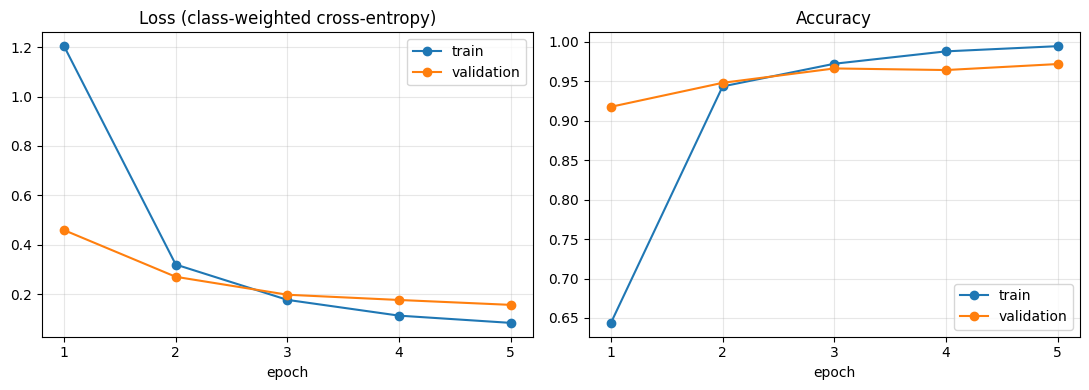

,loss,accuracy,top3_accuracy,val_loss,val_accuracy,val_top3_accuracy
0,1.2037,0.6438,0.8403,0.4592,0.9175,0.9808
1,0.3200,0.9433,0.9923,0.2704,0.9479,0.9939
2,0.1770,0.9720,0.9976,0.1978,0.9661,0.9949
3,0.1131,0.9877,0.9991,0.1766,0.9641,0.9965
4,0.0839,0.9943,0.9991,0.1568,0.9717,0.9954


In [ ]:
# 6.2 Learning curves
if history is not None:
    hist = pd.DataFrame(history.history)
    epochs_axis = np.arange(1, len(hist) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs_axis, hist["loss"], marker="o", label="train")
    axes[0].plot(epochs_axis, hist["val_loss"], marker="o", label="validation")
    axes[0].set_title("Loss (class-weighted cross-entropy)")
    axes[1].plot(epochs_axis, hist["accuracy"], marker="o", label="train")
    axes[1].plot(epochs_axis, hist["val_accuracy"], marker="o", label="validation")
    axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.set_xticks(epochs_axis)
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150)
    plt.show()
    display(hist.round(4))
else:
    print("No training in this run (TRAIN_MODEL = False).")

## 7. Validation results

Accuracy is the Kaggle metric. Because the classes are imbalanced, we also report **balanced accuracy** (the average of per-class recalls), the per-class report and the **confusion matrix**, to check whether the rare classes (mozilla, messenger) are confused with others.

In [ ]:
# 7.1 Predictions on the validation set
@tf.function
def predict_logits_batch(pixel_values):
    return model(pixel_values=pixel_values, training=False).logits

def predict_logits(dataset):
    outputs = []
    for batch in dataset:
        x = batch[0] if isinstance(batch, tuple) else batch
        outputs.append(predict_logits_batch(x).numpy())
    return np.concatenate(outputs)

val_logits = predict_logits(val_ds)
val_pred = val_logits.argmax(axis=1)

val_accuracy = accuracy_score(y_val, val_pred)
val_balanced_accuracy = balanced_accuracy_score(y_val, val_pred)
val_top3 = float(np.mean([y in np.argsort(l)[-3:] for y, l in zip(y_val, val_logits)]))
print(f"Validation accuracy:          {val_accuracy:.4f}")
print(f"Validation balanced accuracy: {val_balanced_accuracy:.4f}")
print(f"Validation top-3 accuracy:    {val_top3:.4f}\n")

report_text = classification_report(y_val, val_pred, labels=np.arange(len(CLASSES)),
                                    target_names=CLASSES, digits=3)
print(report_text)
(OUTPUT_DIR / "validation_report.txt").write_text(report_text)

pd.DataFrame({
    "Id": ids_val,
    "true": [ID_TO_CLASS[i] for i in y_val],
    "predicted": [ID_TO_CLASS[i] for i in val_pred],
}).to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)

Validation accuracy:          0.9717
Validation balanced accuracy: 0.9706
Validation top-3 accuracy:    0.9954

              precision    recall  f1-score   support

       apple      0.956     0.969     0.963       385
      google      0.966     0.984     0.975       376
    whatsapp      0.975     0.954     0.965       329
    facebook      0.979     0.976     0.977       333
     samsung      0.983     0.975     0.979       358
     mozilla      0.962     0.962     0.962        79
   messenger      0.983     0.974     0.978       116

    accuracy                          0.972      1976
   macro avg      0.972     0.971     0.971      1976
weighted avg      0.972     0.972     0.972      1976



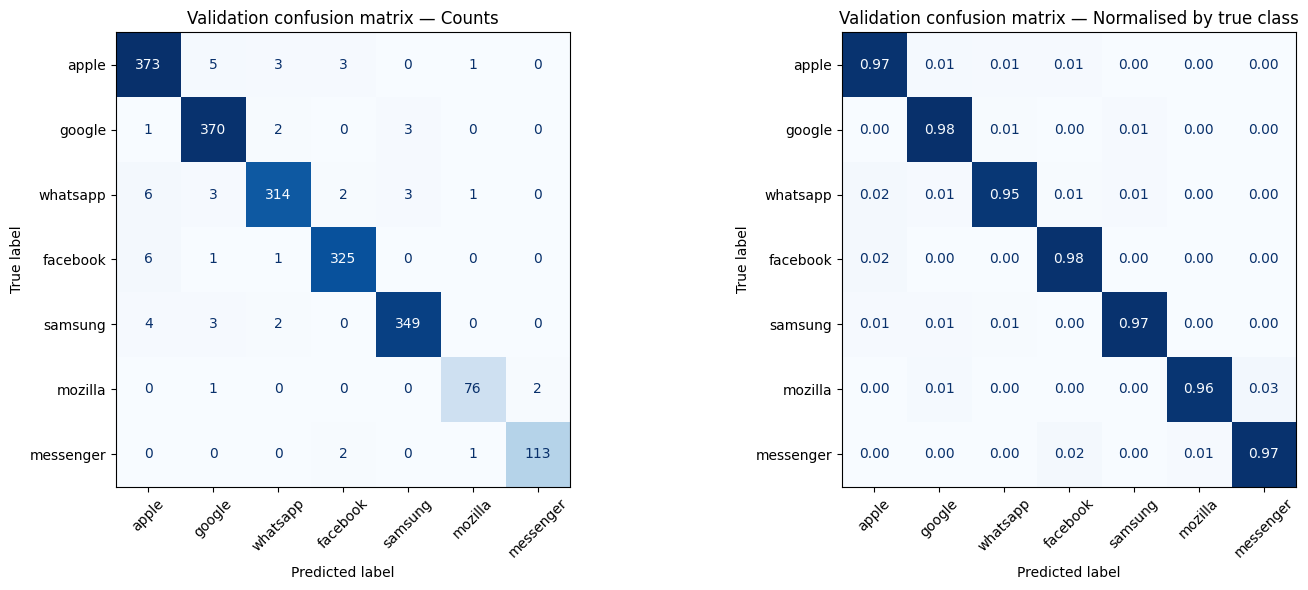

In [ ]:
# 7.2 Confusion matrix (counts and row-normalised = recall per class)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, norm, title in [(axes[0], None, "Counts"), (axes[1], "true", "Normalised by true class")]:
    cm = confusion_matrix(y_val, val_pred, labels=np.arange(len(CLASSES)), normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
    ax.set_title(f"Validation confusion matrix — {title}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 8. Test predictions and `submission.csv`

The test images go through **exactly the same preprocessing** as the training images (`load_resized` + `normalize`). The CSV follows the format of `sample_submission.csv` (same column names and id order) and is checked before saving.

In [ ]:
# 8.1 Predict the test set
X_test = load_images(test_paths, desc="Test images")
test_ds = make_dataset(X_test, labels=None, shuffle=False)
test_pred = predict_logits(test_ds).argmax(axis=1)

submission = pd.DataFrame({ID_COL: test_ids, LABEL_COL: [ID_TO_CLASS[i] for i in test_pred]})

# Format checks
assert list(submission.columns) == [ID_COL, LABEL_COL]
assert len(submission) == len(test_paths) and submission[ID_COL].is_unique
assert set(submission[LABEL_COL]) <= set(CLASSES)

SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
submission.to_csv(SUBMISSION_PATH, index=False)
print("Saved", SUBMISSION_PATH, submission.shape)
display(submission.head())

# Predicted class shares vs. training class shares (a large gap would be suspicious)
display(pd.DataFrame({
    "train share": labels_df["Label"].value_counts(normalize=True),
    "test predicted share": submission[LABEL_COL].value_counts(normalize=True),
}).reindex(CLASSES).round(3))

Test images:   0%|          | 0/9879 [00:00<?, ?it/s]

Saved /content/outputs/submission.csv (9879, 2)


,Id,Label
0,10001,google
1,10002,messenger
2,10003,samsung
3,10004,whatsapp
4,10005,samsung


,train share,test predicted share
Label,,
apple,0.195,0.188
google,0.190,0.196
whatsapp,0.166,0.168
facebook,0.169,0.160
samsung,0.181,0.183
mozilla,0.040,0.043
messenger,0.059,0.062


## 9. Generate `README.md` and `requirements.txt`

The README is written from this run's actual settings, versions and results, so it always matches the code. Fill in the group names and Kaggle team in the configuration cell (1.3), and add the Kaggle score by hand after submitting.

In [ ]:
# 9.1 Write requirements.txt (exact versions used in this run)
requirements_lines = [
    f"tensorflow=={ENV_VERSIONS['tensorflow']}",
    f"tf-keras=={ENV_VERSIONS['tf-keras']}",
    f"transformers=={ENV_VERSIONS['transformers']}",
    f"scikit-learn=={ENV_VERSIONS['scikit-learn']}",
    f"kagglehub=={ENV_VERSIONS['kagglehub']}",
    f"numpy=={ENV_VERSIONS['numpy']}",
    f"pandas=={ENV_VERSIONS['pandas']}",
    f"pillow=={ENV_VERSIONS['pillow']}",
    f"matplotlib=={ENV_VERSIONS['matplotlib']}",
    "tqdm",
]
REQUIREMENTS_PATH = OUTPUT_DIR / "requirements.txt"
REQUIREMENTS_PATH.write_text(
    f"# Python {ENV_VERSIONS['python']} (Google Colab). Generated by {NOTEBOOK_NAME}\n"
    + "\n".join(requirements_lines) + "\n"
)
print(REQUIREMENTS_PATH.read_text())

In [ ]:
# 9.2 Write README.md
run_date = datetime.now().strftime("%Y-%m-%d")
gpu_name = (tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "CPU only")
training_time_text = f"{training_minutes:.0f} min" if training_minutes is not None else "not trained in this run"
best_epoch_text = str(best_epoch) if best_epoch is not None else "-"
versions_table = "\n".join(f"| {name} | {version} |" for name, version in ENV_VERSIONS.items())
class_weights_text = ", ".join(f"{c}: {w:.2f}" for c, w in zip(CLASSES, class_weights))
members_text = ", ".join(GROUP_MEMBERS)
classes_text = ", ".join(CLASSES)

readme = f"""# Emoji vendor classification — fine-tuned Vision Transformer

Computer Vision (IDSI51006) final project — BSc AIDAMS, ESSEC / CentraleSupélec, 2026.

- **Group:** {members_text}
- **Kaggle team:** {KAGGLE_TEAM_NAME}
- **Competition:** [2 - Computer Vision 2026 - BSc AIDAMS - FINAL PROJ]({COMPETITION_URL})
- **Task:** predict which provider drew each emoji image ({classes_text}). Metric: accuracy.

## Approach

| Step | Choice |
|---|---|
| Model | `{MODEL_NAME}` (Vision Transformer, pretrained on ImageNet-21k), new 7-class classification layer, all layers fine-tuned |
| Preprocessing | transparent background filled with white, resized to {IMG_H}x{IMG_W}, normalised with the model's mean/std; no augmentation |
| Class imbalance | class-weighted cross-entropy ({class_weights_text}) |
| Validation | stratified {round((1 - VAL_SIZE) * 100)}/{round(VAL_SIZE * 100)} train/validation split, seed {SEED} |
| Training | AdamW, learning rate {LEARNING_RATE}, {round(WARMUP_RATIO * 100)}% warm-up then linear decay, weight decay {WEIGHT_DECAY}, batch size {BATCH_SIZE}, up to {EPOCHS} epochs, early stopping on validation accuracy (patience {EARLY_STOP_PATIENCE}), best epoch kept |

## Results (run of {run_date})

| Metric | Value |
|---|---|
| Validation accuracy | {val_accuracy:.4f} |
| Validation balanced accuracy | {val_balanced_accuracy:.4f} |
| Validation top-3 accuracy | {val_top3:.4f} |
| Best epoch | {best_epoch_text} |
| Kaggle public leaderboard score | _fill in after submitting_ |
| Training time | {training_time_text} on {gpu_name} |

## How to run (Google Colab — recommended, works from any operating system)

1. **Open the notebook in Colab:** [{NOTEBOOK_NAME}]({COLAB_URL}), or in Colab *File → Upload notebook*.
2. **Runtime → Change runtime type:** *T4 GPU*, and *Runtime version* `2026.07` (recommended: freezes Python 3.12 / TensorFlow 2.20 so Colab updates cannot break the notebook).
3. **Data access — choose one:**
   - **Kaggle API key:** join the competition and accept its rules on Kaggle. Then Kaggle → Settings → API → *Create New Token*. In Colab's 🔑 *Secrets* panel, add `KAGGLE_USERNAME` and `KAGGLE_KEY` (or `KAGGLE_API_TOKEN`) with notebook access on. The data is downloaded automatically.
   - **Manual upload:** download the data zip from the competition's *Data* tab and drag it into Colab's *Files* panel (`/content`). It is found and unzipped automatically.
4. **Runtime → Run all.** On the first run, the install cell installs the pinned library versions and restarts the session (a "session crashed" message is expected). Then **Runtime → Run all again**.
5. The whole run takes roughly 30–60 minutes on a T4 GPU. At the end, `submission.csv`, `README.md` and `requirements.txt` are downloaded through the browser (allow multiple downloads if asked). Nothing is written to Google Drive.

### Running locally (optional, not the tested route)

Python {ENV_VERSIONS['python']}, then `pip install -r requirements.txt` and run the notebook in Jupyter. Place the competition zip next to the notebook, or set Kaggle credentials as environment variables. A GPU is strongly recommended.

## Reproducibility

- Exact library versions are pinned in the notebook's first cell and listed in `requirements.txt`.
- Seed {SEED} fixes the train/validation split, the shuffling order and the initialisation of the classification layer.
- GPU computations can still vary very slightly between runs. Set `DETERMINISTIC = True` in the configuration cell for bit-identical runs (slower).
- All settings are in one configuration cell (section 1.3 of the notebook).

Environment of this run:

| Package | Version |
|---|---|
{versions_table}

## Outputs

| File | Content |
|---|---|
| `submission.csv` | test predictions in the Kaggle format (`{ID_COL}`, `{LABEL_COL}`) |
| `requirements.txt` | exact library versions |
| `outputs/training_log.csv`, `outputs/learning_curves.png` | loss / accuracy per epoch |
| `outputs/validation_report.txt`, `outputs/confusion_matrix.png`, `outputs/validation_predictions.csv` | validation results |
| `outputs/vit_emoji_model/` | trained model (only inside the Colab session unless `DOWNLOAD_MODEL = True`) |

## Repository

- `{NOTEBOOK_NAME}` — final pipeline (this README is generated by it)
- `submission.ipynb` — earlier experiments (custom CNN, ResNet101 transfer learning, first ViT runs)
- `README.md`, `requirements.txt`

## AI usage

The final notebook was reorganised, cleaned up and documented with the help of Claude (Anthropic), starting from our own experimental notebook. The prompts used are listed in the "AI usage" section at the top of the notebook. The experiments, modelling decisions and the report are our own work.
"""

README_PATH = OUTPUT_DIR / "README.md"
README_PATH.write_text(readme, encoding="utf-8")
print(f"Saved {README_PATH}\n")
print(readme)

Saved /content/outputs/README.md

# Emoji vendor classification — fine-tuned Vision Transformer

Computer Vision (IDSI51006) final project — BSc AIDAMS, ESSEC / CentraleSupélec, 2026.

- **Group:** Name 1, Name 2, Name 3, Name 4
- **Kaggle team:** TODO
- **Competition:** [2 - Computer Vision 2026 - BSc AIDAMS - FINAL PROJ](https://www.kaggle.com/t/521819a4ff2d4c7a81511fdcb4709a50)
- **Task:** predict which provider drew each emoji image (apple, google, whatsapp, facebook, samsung, mozilla, messenger). Metric: accuracy.

## Approach

| Step | Choice |
|---|---|
| Model | `google/vit-base-patch16-224-in21k` (Vision Transformer, pretrained on ImageNet-21k), new 7-class classification layer, all layers fine-tuned |
| Preprocessing | transparent background filled with white, resized to 224x224, normalised with the model's mean/std; no augmentation |
| Class imbalance | class-weighted cross-entropy (apple: 0.73, google: 0.75, whatsapp: 0.86, facebook: 0.85, samsung: 0.79, mozilla: 3.55, mess

## 10. Download the output files

The files are downloaded through the browser, the same way for every file (no Google Drive access is needed). The full `outputs/` folder also stays available in the Colab *Files* panel until the session ends.

In [ ]:
# 10.1 Download
files_to_download = [SUBMISSION_PATH, README_PATH, REQUIREMENTS_PATH]

if DOWNLOAD_MODEL and MODEL_DIR.exists():
    model_zip = shutil.make_archive(str(OUTPUT_DIR / "vit_emoji_model"), "zip", MODEL_DIR)
    files_to_download.append(Path(model_zip))

if IN_COLAB:
    for f in files_to_download:
        files.download(str(f))
        time.sleep(1)   # small pause so the browser does not drop consecutive downloads
    print("Downloads started:", [f.name for f in files_to_download])
else:
    print("Not in Colab - the files are in:", OUTPUT_DIR.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloads started: ['submission.csv', 'README.md', 'requirements.txt']


In [ ]:
# 10.2 Final summary
print("Run finished")
print(f"  Validation accuracy:          {val_accuracy:.4f}")
print(f"  Validation balanced accuracy: {val_balanced_accuracy:.4f}")
print(f"  Submission file:              {SUBMISSION_PATH} ({len(submission)} rows)")
print("Next: upload submission.csv on the Kaggle competition page (max 5 submissions per day).")